# Étape 12 : comparaison finale des méthodes d'allocation

Deux comparaisons, avec les mêmes quatre méthodes :
1. **sur notre univers d'actions** (S&P 500, 2012-2026, nets de frais), face à l'univers pondéré par la capitalisation ;
2. **sur les facteurs de Fama et French** (1975-2026), face au marché américain.

Méthodes : score équipondéré (étape 9), ERC historique (étape 9), ERC GARCH (étape 10.2), ERC GARCH + contrôle du risque actif par CP (étape 11).

## 1. Données et outils des étapes précédentes

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
from scipy.stats import chi2
from arch import arch_model

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
print(f"{len(scores):,}".replace(",", " "), "scores (mois, action)")
print(f"Corrélation entre les deux scores : {scores.corr().iloc[0, 1]:.2f}")

72 741 scores (mois, action)
Corrélation entre les deux scores : 0.92


In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

In [9]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

In [10]:
FACT = list(STYLES.values())
SIX = ["Mkt-RF"] + FACT


def previsions(colonnes, debut, spec=dict(vol="GARCH", p=1, q=1, dist="t")):
    # Variance prévue pour le mois t+1, fin t, avec les seules données jusqu'à t.
    sortie = {}
    for k in colonnes:
        x = 100 * facteurs[k]
        params, valeurs = None, {}
        for m in facteurs.loc[debut:].index:
            modele = arch_model(x.loc[:m], mean="Constant", **spec)
            if params is None or m.month == 12:
                params = modele.fit(disp="off", show_warning=False).params
            valeurs[m + 1] = modele.fix(params).forecast(horizon=1, reindex=False).variance.iloc[-1, 0] / 1e4
        sortie[k] = pd.Series(valeurs)
    return pd.DataFrame(sortie)


prev = previsions(SIX, "1972-12")


def cov_facteurs(m, colonnes):
    # Covariance prévue pour le mois m+1 : volatilités GARCH × corrélations des 60 derniers mois
    sigma = np.sqrt(prev.loc[m + 1, colonnes].values)
    return np.outer(sigma, sigma) * facteurs.loc[:m, colonnes].iloc[-60:].corr().values


poids_garch = pd.DataFrame({m: poids_erc(cov_facteurs(m, FACT)) for m in mois}, index=FACT).T
scores["score_erc_garch"] = score_final(poids_garch)
cibles = poids_cibles(scores["score_erc_garch"])
indice = univers_capi()
strategie = backtest(cibles)
reference = backtest(indice)
actif = strategie["brut"] - reference["brut"]
print(f"Portefeuille de l'étape 10.2 : écart de suivi {actif.std() * np.sqrt(12):.1%} par an, "
      f"pire mois {actif.min():+.1%}, {actif.index[0]} à {actif.index[-1]}")

Portefeuille de l'étape 10.2 : écart de suivi 5.9% par an, pire mois -5.7%, 2012-03 à 2026-08


In [11]:
rex = rendements.sub(rf.reindex(rendements.index), axis=0)
F = facteurs.reindex(rendements.index)[SIX]


def betas_du_mois(m, tickers):
    fen = rex.loc[:m].iloc[-60:]
    X = np.column_stack([np.ones(len(fen)), F.loc[fen.index].values])
    b, s = {}, {}
    for t in tickers:
        if t not in fen.columns:
            continue
        y = fen[t].values
        ok = ~np.isnan(y)
        if ok.sum() < 36:
            continue
        coef, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)
        res = y[ok] - X[ok] @ coef
        b[t] = coef[1:]
        s[t] = res.std(ddof=7)
    return pd.DataFrame(b, index=SIX).T, pd.Series(s)


lignes, sans_histo = {}, []
for m in cibles:
    w_s, w_b = cibles[m], indice[m]
    d = w_s.subtract(w_b, fill_value=0)
    B, s = betas_du_mois(m, d.index)
    manque = d.index.difference(B.index)
    sans_histo.append(d[manque].abs().sum() / d.abs().sum())
    B = B.reindex(d.index).fillna(B.median())
    s = s.reindex(d.index).fillna(s.median())
    e = d @ B
    var_fact = e.values @ cov_facteurs(m, SIX) @ e.values
    var_prop = float((d ** 2 * s ** 2).sum())
    lignes[m + 1] = {**e.add_prefix("expo ").to_dict(), "vol facteurs": np.sqrt(var_fact),
                     "vol propre": np.sqrt(var_prop), "sigma": np.sqrt(var_fact + var_prop)}
modele = pd.DataFrame(lignes)
modele = modele.T
sigma = modele["sigma"]
print(f"Part des poids actifs sans assez d'historique (moyenne) : {np.mean(sans_histo):.1%}")

Part des poids actifs sans assez d'historique (moyenne) : 1.3%


In [12]:
ALPHA, GAMMA, FENETRE, MINIMUM = 0.10, 0.005, 60, 24


def intervalles(a, sigma, methode, alpha=ALPHA, gamma=GAMMA):
    score = (a.abs() / sigma).dropna()
    alpha_t, sortie = alpha, {}
    for m in score.index:
        passe = score.loc[:m - 1].iloc[-FENETRE:]
        if len(passe) < MINIMUM:
            continue
        if methode == "normale":
            q = norm.ppf(1 - alpha / 2)
        else:
            n = len(passe)
            niveau = np.ceil((n + 1) * (1 - alpha_t)) / n
            q = passe.max() if niveau >= 1 else (0.0 if niveau <= 0 else np.quantile(passe, niveau, method="higher"))
        dehors = bool(score[m] > q)
        sortie[m] = {"q": q, "borne": q * sigma[m], "dehors": dehors, "alpha": alpha_t}
        if methode == "aci":
            alpha_t += gamma * (alpha - dehors)
    return pd.DataFrame(sortie).T.astype({"q": float, "borne": float, "dehors": bool, "alpha": float})


def kupiec(dehors, alpha=ALPHA):
    n, x = len(dehors), int(dehors.sum())
    p = x / n
    lr = -2 * ((n - x) * np.log(1 - alpha) + x * np.log(alpha)
               - ((n - x) * np.log(1 - p) + (x * np.log(p) if x else 0)))
    return chi2.sf(lr, 1)


def christoffersen(dehors):
    # Indépendance des sorties : une sortie rend-elle la suivante plus probable ?
    x = dehors.astype(int).values
    n00 = ((x[:-1] == 0) & (x[1:] == 0)).sum(); n01 = ((x[:-1] == 0) & (x[1:] == 1)).sum()
    n10 = ((x[:-1] == 1) & (x[1:] == 0)).sum(); n11 = ((x[:-1] == 1) & (x[1:] == 1)).sum()
    p01, p11, p = n01 / (n00 + n01), (n11 / (n10 + n11) if n10 + n11 else 0), (n01 + n11) / len(x[1:])
    ll = lambda q, a, b: (a * np.log(1 - q) if a else 0) + (b * np.log(q) if b and q > 0 else 0)
    lr = -2 * (ll(p, n00 + n10, n01 + n11) - ll(p01, n00, n01) - ll(p11, n10, n11))
    return chi2.sf(lr, 1)


def evaluer(a, sigma, regime):
    lignes = {}
    for nom, methode in [("Quantile normal (1,645)", "normale"), ("CP simple", "cp"), ("CP adaptative (ACI)", "aci")]:
        iv = intervalles(a, sigma, methode)
        haut = regime.reindex(iv.index)
        lignes[nom] = {"mois testés": len(iv), "couverture": 1 - iv["dehors"].mean(),
                       "p Kupiec (couverture = 90 %)": kupiec(iv["dehors"]),
                       "p Christoffersen (indépendance)": christoffersen(iv["dehors"]),
                       "couverture, risque prévu élevé": 1 - iv.loc[haut, "dehors"].mean(),
                       "couverture, risque prévu faible": 1 - iv.loc[~haut, "dehors"].mean(),
                       "sorties par le bas": (a.reindex(iv.index) < -iv["borne"]).mean(),
                       "q moyen": iv["q"].mean(), "largeur moyenne (± annualisée)": (iv["borne"] * np.sqrt(12)).mean()}
    return pd.DataFrame(lignes).T

In [13]:
BUDGET = 0.025


def portefeuille_controle(iv, budget=BUDGET):
    k = np.minimum(1.0, budget / iv["borne"])
    sortie = {}
    for m in cibles:
        km = k.get(m + 1, 1.0)
        w = (indice[m] * (1 - km)).add(cibles[m] * km, fill_value=0)
        sortie[m] = w[w > 0]
    return sortie, k

## 2. Sur notre univers d'actions (mars 2012 à août 2026)

- Toutes les méthodes utilisent les mêmes actions, les mêmes z-scores, la même sélection (30 %, tampon à 40 %), la même pondération capitalisation × (1 + score), le même plafond et les mêmes frais (0,10 % par dollar échangé).
- Seule change la façon de pondérer les facteurs dans le score, puis, pour la dernière, le contrôle du risque actif.
- Le contrôle par CP démarre en mars 2014, après 24 mois de calibration. Avant, ce portefeuille est identique à l'ERC GARCH.

In [14]:
a = actif.reindex(sigma.index)
iv_aci = intervalles(a, sigma, "aci")
ctrl, k_actions = portefeuille_controle(iv_aci)

methodes = {
    "Équipondéré": backtest(poids_cibles(scores["score_equipondere"])),
    "ERC": backtest(poids_cibles(scores["score_erc"])),
    "ERC GARCH": strategie,
    "ERC GARCH + CP": backtest(ctrl),
}
periode = reference.index
nets = {k: v["net"] for k, v in methodes.items()}
nets["Univers (capitalisation)"] = reference["net"]
nets["SPY"] = rend_etf["SPY"].reindex(periode)


def metriques(r, bench, rotation=None):
    r, bench = r.dropna(), bench.reindex(r.dropna().index)
    exces = r - rf.reindex(r.index)
    valeur = (1 + r).cumprod()
    act = r - bench
    moy, t, _ = test_moyenne(act) if act.abs().sum() > 0 else (0, np.nan, np.nan)
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "volatilité": r.std() * np.sqrt(12),
        "Sharpe": exces.mean() / exces.std() * np.sqrt(12),
        "perte maximale": (valeur / valeur.cummax() - 1).min(),
        "rendement actif annuel": 12 * act.mean(),
        "écart de suivi": act.std() * np.sqrt(12),
        "ratio d'information": act.mean() / act.std() * np.sqrt(12) if act.std() > 0 else np.nan,
        "t (Newey-West)": t,
        "pire mois relatif": act.min(),
        "mois sous −2,5 %": int((act < -0.025).sum()),
        "rotation annuelle": np.nan if rotation is None else rotation.iloc[1:].mean() * 12,
    })


FORMATS = {"rendement annuel": "{:.1%}", "volatilité": "{:.1%}", "Sharpe": "{:.2f}", "perte maximale": "{:.1%}",
           "rendement actif annuel": "{:+.2%}", "écart de suivi": "{:.1%}", "ratio d'information": "{:+.2f}",
           "t (Newey-West)": "{:+.2f}", "pire mois relatif": "{:+.1%}", "mois sous −2,5 %": "{:.0f}",
           "rotation annuelle": "{:.0%}"}
tableau_actions = pd.DataFrame({k: metriques(r, reference["net"], methodes[k]["rotation"] if k in methodes else None)
                                for k, r in nets.items()}).T
print(f"{periode[0]} à {periode[-1]}, {len(periode)} mois, nets de frais ; benchmark : univers pondéré par la capitalisation")
tableau_actions.style.format(FORMATS, na_rep="")

2012-03 à 2026-08, 174 mois, nets de frais ; benchmark : univers pondéré par la capitalisation


,rendement annuel,volatilité,Sharpe,perte maximale,rendement actif annuel,écart de suivi,ratio d'information,t (Newey-West),pire mois relatif,"mois sous −2,5 %",rotation annuelle
Équipondéré,15.6%,15.8%,0.90,-28.2%,+0.77%,7.2%,+0.11,+0.38,-6.6%,12,315%
ERC,14.7%,15.4%,0.87,-23.2%,-0.12%,6.4%,-0.02,-0.07,-5.9%,13,278%
ERC GARCH,15.5%,15.1%,0.92,-22.5%,+0.53%,5.9%,+0.09,+0.30,-5.7%,11,333%
ERC GARCH + CP,15.7%,14.9%,0.95,-22.5%,+0.70%,4.0%,+0.17,+0.56,-3.6%,4,296%
Univers (capitalisation),15.1%,14.0%,0.96,-23.6%,+0.00%,0.0%,,,+0.0%,0,
SPY,14.6%,14.0%,0.93,-23.9%,-0.41%,0.8%,-0.55,-2.64,-0.7%,0,


In [15]:
# Rendement actif annuel par sous-période (contre l'univers)
sous_periodes = {"2012-2016": ("2012-03", "2016-12"), "2017-2021": ("2017-01", "2021-12"), "2022-2026": ("2022-01", "2026-08")}
pd.DataFrame({sp: {k: 12 * (nets[k] - reference["net"]).loc[d:f].mean() for k in methodes}
              for sp, (d, f) in sous_periodes.items()}).style.format("{:+.2%}")

,2012-2016,2017-2021,2022-2026
Équipondéré,+2.75%,-2.15%,+1.86%
ERC,+2.46%,-0.47%,-2.42%
ERC GARCH,+2.90%,+0.55%,-1.93%
ERC GARCH + CP,+2.85%,+1.18%,-2.04%


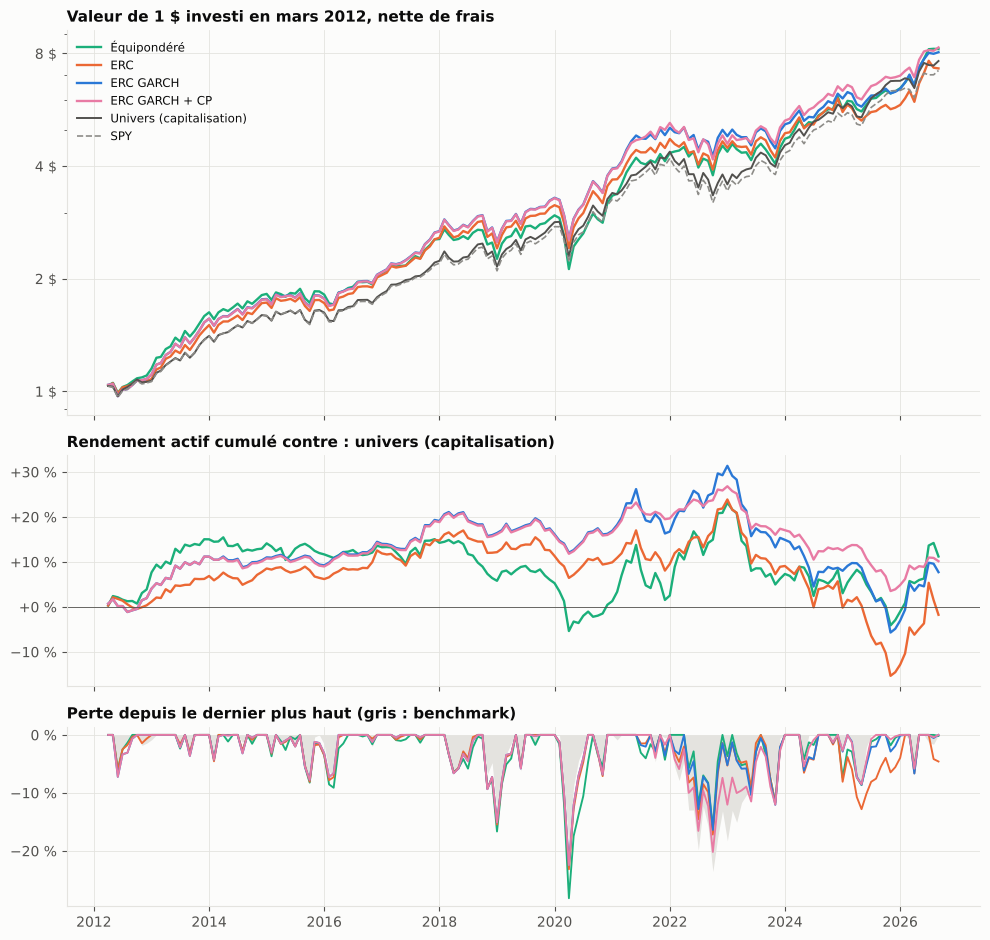

In [16]:
COUL = {"Équipondéré": AQUA, "ERC": ORANGE, "ERC GARCH": BLEU, "ERC GARCH + CP": MAGENTA}


def graphique(nets, bench_nom, periode, titre_valeur, nom_fichier, pas_annees, ticks):
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.8, 1.4]})
    d = periode.to_timestamp(how="end")
    bench = nets[bench_nom].reindex(periode)
    for nom, r in nets.items():
        r = r.reindex(periode)
        couleur, style, lw = (TEXTE2, "-", 1.4) if nom == bench_nom else (GRIS, "--", 1.2) if nom == "SPY" else (COUL[nom], "-", 1.7)
        v = (1 + r).cumprod()
        ax1.plot(d, v, color=couleur, ls=style, lw=lw, label=nom)
        if nom in COUL:
            ax2.plot(d, 100 * (r - bench).cumsum(), color=couleur, lw=lw, label=nom)
            ax3.plot(d, 100 * (v / v.cummax() - 1), color=couleur, lw=lw * 0.8)
    v = (1 + bench).cumprod()
    ax3.fill_between(d, 100 * (v / v.cummax() - 1), 0, color=GRILLE, lw=0, label=bench_nom)
    ax1.set_yscale("log")
    ax1.set_yticks(ticks)
    ax1.yaxis.set_major_formatter(virgule("{:.0f} $"))
    ax1.yaxis.set_minor_formatter(plt.NullFormatter())
    ax1.set_title(titre_valeur)
    ax1.legend(loc="upper left", fontsize=8.5)
    ax2.axhline(0, color=TEXTE2, lw=0.6)
    ax2.yaxis.set_major_formatter(virgule("{:+.0f} %"))
    ax2.set_title(f"Rendement actif cumulé contre : {bench_nom.lower()}")
    ax3.yaxis.set_major_formatter(virgule("{:.0f} %"))
    ax3.set_title("Perte depuis le dernier plus haut (gris : benchmark)")
    ax3.xaxis.set_major_locator(mdates.YearLocator(pas_annees))
    ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.tight_layout()
    sauver(fig, nom_fichier)
    plt.show()


graphique(nets, "Univers (capitalisation)", periode, "Valeur de 1 $ investi en mars 2012, nette de frais",
          "final_actions.png", 2, [1, 2, 4, 8])

## 3. Sur les facteurs de Fama et French (janvier 1975 à août 2026)

**Construction** (comme à l'étape 11.5) : portefeuille = **marché + $\sum_k b_k\, f_k$**.
- $f_k$ : rendement long-short du facteur $k$ (SMB, HML, RMW, CMA, Mom), autofinancé : l'ajouter au marché est un pari actif, sans capital supplémentaire.
- $b_k$ : poids du facteur, selon la méthode :
  - **équipondéré** : 20 % chacun ;
  - **ERC** : covariance des 60 derniers mois ;
  - **ERC GARCH** : volatilités GARCH × corrélations 60 mois ;
  - **ERC GARCH + CP** : mêmes poids, multipliés par $k_t = \min(1, 2{,}5\,\% / (q_t\,\hat\sigma_{a,t+1}))$ (étape 11).
- **Benchmark : le marché** (Mkt-RF + taux sans risque). C'est le bon benchmark : avec $b = 0$, on détient exactement le marché.
- Sans frais : les séries de French n'en ont pas. Elles incluent les petites capitalisations, donc ce portefeuille n'est pas directement investissable. Il mesure ce que l'allocation entre facteurs aurait apporté **en théorie**.
- Début en 1975 : il faut des prévisions GARCH (fin 1972) puis 24 mois de calibration de la CP.

In [17]:
dates_f = prev.index[:-1] - 1
b = {
    "Équipondéré": pd.DataFrame(0.2, index=dates_f, columns=FACT),
    "ERC": pd.DataFrame({m: poids_erc(facteurs.loc[:m, FACT].iloc[-60:].cov().values) for m in dates_f}, index=FACT).T,
    "ERC GARCH": pd.DataFrame({m: poids_erc(cov_facteurs(m, FACT)) for m in dates_f}, index=FACT).T,
}
actifs_f = {k: pd.Series({m + 1: float(w.loc[m] @ facteurs.loc[m + 1, FACT]) for m in dates_f}) for k, w in b.items()}
sigma_f = pd.Series({m + 1: np.sqrt(b["ERC GARCH"].loc[m].values @ cov_facteurs(m, FACT) @ b["ERC GARCH"].loc[m].values)
                     for m in dates_f})
iv_f = intervalles(actifs_f["ERC GARCH"], sigma_f, "aci")
k_f = np.minimum(1.0, BUDGET / iv_f["borne"])
per_f = iv_f.index
actifs_f["ERC GARCH + CP"] = k_f * actifs_f["ERC GARCH"].reindex(per_f)
marche = facteurs["Mkt-RF"] + facteurs["RF"]
nets_f = {k: (marche + a).reindex(per_f) for k, a in actifs_f.items()}
nets_f["Marché"] = marche.reindex(per_f)
tableau_f = pd.DataFrame({k: metriques(r, marche) for k, r in nets_f.items()}).T.drop(columns="rotation annuelle")
print(f"{per_f[0]} à {per_f[-1]}, {len(per_f)} mois, sans frais ; benchmark : le marché")
tableau_f.style.format(FORMATS, na_rep="")

1975-01 à 2026-08, 620 mois, sans frais ; benchmark : le marché


,rendement annuel,volatilité,Sharpe,perte maximale,rendement actif annuel,écart de suivi,ratio d'information,t (Newey-West),pire mois relatif,"mois sous −2,5 %"
Équipondéré,17.0%,15.0%,0.85,-46.0%,+3.60%,4.8%,+0.75,+4.59,-7.1%,21
ERC,16.6%,15.0%,0.83,-46.6%,+3.31%,4.2%,+0.79,+4.86,-7.3%,11
ERC GARCH,16.8%,15.0%,0.84,-44.5%,+3.43%,4.2%,+0.82,+5.15,-8.4%,10
ERC GARCH + CP,16.2%,15.1%,0.80,-44.5%,+2.95%,3.3%,+0.89,+5.53,-4.4%,3
Marché,12.8%,15.5%,0.59,-50.3%,+0.00%,0.0%,,,+0.0%,0


In [18]:
# Poids moyens des facteurs et part des paris conservée
pd.concat({k: w.loc[per_f[0] - 1:].mean() for k, w in b.items()}, axis=1).T.assign(
    **{"k moyen": [1, 1, 1]}).style.format("{:.0%}").format("{:.2f}", subset=["k moyen"])

,SMB,HML,RMW,CMA,Mom,k moyen
Équipondéré,20%,20%,20%,20%,20%,1.00
ERC,21%,15%,32%,20%,13%,1.00
ERC GARCH,19%,15%,32%,19%,14%,1.00


In [19]:
# Rendement actif annuel et ratio d'information par sous-période (contre le marché)
sp_f = {"1975-1989": ("1975-01", "1989-12"), "1990-2011": ("1990-01", "2011-12"), "2012-2026": ("2012-01", "2026-08")}
lignes = {}
for nom in actifs_f:
    for sp, (d, f) in sp_f.items():
        act = (nets_f[nom] - nets_f["Marché"]).loc[d:f]
        lignes[(nom, sp)] = {"rendement actif annuel": 12 * act.mean(), "ratio d'information": act.mean() / act.std() * np.sqrt(12),
                             "t (Newey-West)": test_moyenne(act)[1]}
pd.DataFrame(lignes).T.unstack(1).style.format("{:+.2f}").format(
    "{:+.1%}", subset=[c for c in pd.DataFrame(lignes).T.unstack(1).columns if c[0] == "rendement actif annuel"])

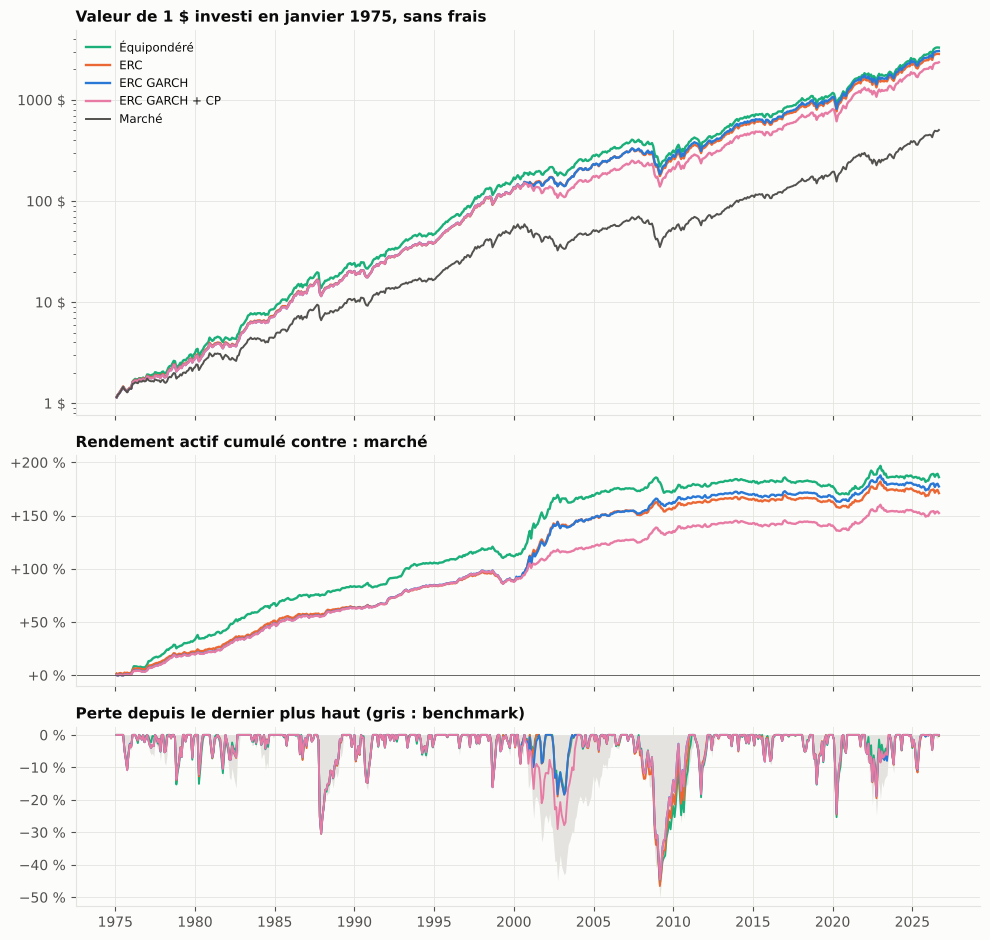

In [20]:
graphique(nets_f, "Marché", per_f, "Valeur de 1 $ investi en janvier 1975, sans frais", "final_french.png", 5,
          [1, 10, 100, 1000])